# NBA Pay vs. Performance in the 2021-22 Season

Julia Rasul, INFO 4120 Midterm Project, Part One

In [1]:
#set up
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import kagglehub
import pandas as pd
import numpy as np
import difflib
import matplotlib.pyplot as plt
plt.rcParams['text.parse_math'] = False
pd.set_option('display.html.use_mathjax', False)

# settings used in more than one analysis
min_games = 20
low_pay_cutoff = 1000000

# Section 1: Executive Summary

This project looks at how NBA player salaries relate to performance, draft position and injuries during the 2021-22 season. I combined three datasets covering player stats and salaries, injured list placements and draft history, which gave a final dataset of 540 players. Teams spend millions of dollars on many contracts, so it is interesting to see whether higher salaries line up with more production on the court and how pay relates to a player’s path into the league. Salary had a strong positive correlation with points per game (0.74) and moderately strong correlations with rebounds (0.64) and assists (0.62), although much of the scoring advantage came from higher paid players playing more minutes. Players drafted earlier earned more and scored more than later picks and undrafted players. Higher paid players were also placed on the injured list more often, partly because they play more minutes, and among players with similar minutes the gap was smaller and based on small groups.

# Section 2: Research Questions

1) How strongly is a player’s salary related to their points, rebounds, and assists per game?
2) Do high draft picks earn more and score more than second round and undrafted players?
3) Are higher paid players placed on the injured list more often than lower paid players?

# Section 3: The Data

## Data sources used:

NBA Player Stats and Salaries 2010-2025: https://www.kaggle.com/datasets/ratin21/nba-player-stats-and-salaries-2010-2025


NBA Injury Stats (1951 - 2023): https://www.kaggle.com/datasets/loganlauton/nba-injury-stats-1951-2023

NBA Players: https://www.kaggle.com/datasets/justinas/nba-players-data



In [2]:
# clean Stats data

season = 2022
stats_path = kagglehub.dataset_download("ratin21/nba-player-stats-and-salaries-2010-2025")

stats = pd.read_csv(stats_path + '/NBA Player Stats and Salaries_2010-2025.csv')

stats = stats[(stats['Year'] == season)]
stats = stats[['Player', 'Year', 'Pos', 'G', 'MP', 'PTS', 'TRB', 'AST', 'Salary']]
stats.columns = ['player', 'year', 'position','games', 'minutes', 'points', 'rebounds', 'assists', 'salary']
stats = stats.set_index('player')
stats.head()

,year,position,games,minutes,points,rebounds,assists,salary
player,,,,,,,,
Stephen Curry,2022,PG,64,34.5,25.5,5.2,6.3,52938707
James Harden,2022,PG-SG,65,37.2,22.0,7.7,10.3,51238730
Russell Westbrook,2022,PG,78,34.3,18.5,7.4,7.1,51123449
Kevin Durant,2022,PF,55,37.2,29.9,7.4,6.4,48588451
LeBron James,2022,SF,56,37.2,30.3,8.2,6.2,47619020


Stats and salary data

I loaded the player stats and salaries file and kept only the 2021-22 season (Year 2022 in this file), which gives 540 players. I kept the columns I need for my questions: position, games, minutes, points, rebounds, assists and salary. Then I renamed them to short lowercase names so they are easier to work with.

In [3]:
# clean injury data
season_start = '2021-10-19'
season_end = '2022-04-10'
injury_path = kagglehub.dataset_download("loganlauton/nba-injury-stats-1951-2023")
injury = pd.read_csv(injury_path + '/NBA Player Injury Stats(1951 - 2023).csv')

injury['Date'] = pd.to_datetime(injury['Date'])
injury = injury[(injury['Date'] >= season_start) & (injury['Date'] <= season_end)]

# remove COVID health and safety protocol placements
injury = injury[~injury['Notes'].str.contains('health and safety', case=False, na=False)]

# count placements kept and how many list no reason (used in the limitations)
placements = injury[injury['Relinquished'].notna()]
no_reason = (placements['Notes'].fillna('').str.strip() == 'placed on IL').sum()
not_with_team = placements['Notes'].str.contains('not with team', case=False, na=False).sum()
print(f"Placements kept: {len(placements)}, with no reason listed: {no_reason}, listed as not with team: {not_with_team}")

injury = injury.rename(columns={'Relinquished': 'player', 'Date': 'date', 'Team': 'team'})
injury = injury[['player', 'date', 'team']]

# Oct to Dec dates count toward the next year's season (2021-22 = 2022)
injury['year'] = np.where(injury['date'].dt.month >= 8, injury['date'].dt.year + 1, injury['date'].dt.year)
# rows with no Relinquished name are activations, groupby drops them
injury_counts = injury.groupby(['player', 'year']).size().reset_index(name='times_injured')
injury_counts.head()

Placements kept: 1105, with no reason listed: 138, listed as not with team: 4


,player,year,times_injured
0,Aaron Gordon,2022,5
1,Aaron Henry,2022,4
2,Aaron Holiday,2022,2
3,Aaron Nesmith,2022,2
4,Aaron Wiggins,2022,1


Injury data

The injury file lists every injured list transaction since 1951, so I kept only the 2021-22 regular season (October 19, 2021 to April 10, 2022). I removed placements for COVID health and safety protocols because those are not physical injuries and would make players look injury prone during the Omicron wave. Then I counted how many times each player was placed on the injured list. The printed line shows how many placements I kept, how many list no reason at all, and how many only say the player was not with the team, which I come back to in the limitations.

In [4]:
# clean draft data

season_year = '2021-22'
draft_path = kagglehub.dataset_download("justinas/nba-players-data")

draft = pd.read_csv(draft_path + '/all_seasons.csv')
draft = draft.drop(['gp','pts','reb','ast', 'net_rating', 'oreb_pct', 'dreb_pct', 'usg_pct', 'ts_pct', 'ast_pct', 'Unnamed: 0', 'age', 'team_abbreviation', 'player_height', 'player_weight','college','country'], axis=1)
draft = draft[(draft['season'] == season_year)]
draft = draft.set_index('player_name')

draft.head()

,draft_year,draft_round,draft_number,season
player_name,,,,
Usman Garuba,2021,1,23,2021-22
Vlatko Cancar,2017,2,49,2021-22
Vit Krejci,2020,2,37,2021-22
Victor Oladipo,2013,1,2,2021-22
Vernon Carey Jr.,2020,2,32,2021-22


Draft data

This file has draft information for every player by season. I kept only the 2021-22 season and the draft year, round and pick columns, and dropped the other columns, including stats the first file already covers and details like height and college that my questions do not use.

In [5]:
# clean names in all 3 files

def clean_name(name):
    name = name.split('(')[0].split('/')[-1]
    name = name.strip().replace('.', '')
    for suffix in [' Jr', ' Sr', ' III', ' II', ' IV']:
        if name.endswith(suffix):
            name = name[:-len(suffix)]
    return name

# match injury file nicknames to stats names (ex. Moe Wagner -> Moritz Wagner)
# same last name and same first 2 letters of first name, only if there is 1 match
def match_nickname(name, stats_names):
    if name in stats_names:
        return name
    first = name.split(' ')[0]
    last = name.split(' ')[-1]
    matches = []
    for player in stats_names:
        if player.split(' ')[-1] == last and player[:2] == first[:2]:
            matches.append(player)
    if len(matches) == 1:
        print(f"{name} -> {matches[0]}")
        return matches[0]
    return name

stats = stats.reset_index()
stats['player'] = stats['player'].apply(clean_name)

stats_names = stats['player'].tolist()
injury_counts['player'] = injury_counts['player'].apply(clean_name)
injury_counts['player'] = injury_counts['player'].apply(match_nickname, stats_names=stats_names)
injury_counts = injury_counts.groupby(['player', 'year'])['times_injured'].sum().reset_index()

draft = draft.reset_index()
draft['player_name'] = draft['player_name'].apply(clean_name)

Moe Wagner -> Moritz Wagner
Wes Matthews -> Wesley Matthews


Cleaning player names

The three files do not always spell names the same way. For example, one file writes "P.J. Dozier" and another writes "PJ Dozier", or one uses a nickname like "Moe Wagner" instead of "Moritz Wagner". My clean_name function removes periods and suffixes like Jr. and III. My match_nickname function links a nickname to the full name when the last name and the first two letters match only one player.

In [6]:
# merge all 3 files 

df = stats.merge(injury_counts, on=['player', 'year'], how='left')
print(f"Players with no injury rows before filling: {df['times_injured'].isnull().sum()}")
df['times_injured'] = df['times_injured'].fillna(0).astype(int)

draft_cols = draft.rename(columns={'player_name': 'player'})
draft_cols['year'] = draft_cols['season'].str[:4].astype(int) + 1
draft_cols = draft_cols.drop(columns='season')

# match names that are spelled very close
for player, year in zip(stats['player'], stats['year']):
    year_names = draft_cols[draft_cols['year'] == year]['player'].tolist()
    if player not in year_names:
        match = difflib.get_close_matches(player, year_names, n=1, cutoff=0.8)
        if match:
            print(f"{match[0]} -> {player} ({year})")
            draft_cols.loc[(draft_cols['player'] == match[0]) & (draft_cols['year'] == year), 'player'] = player

df = df.merge(draft_cols, on=['player', 'year'], how='inner')
df = df.set_index('player')
stats = stats.set_index('player')

df.loc[['Moritz Wagner', 'Wesley Matthews'], 'times_injured']

Players with no injury rows before filling: 174
Alekesej Pokusevski -> Aleksej Pokusevski (2022)
Trevon Scott -> Tre Scott (2022)


player
Moritz Wagner      2
Wesley Matthews    2
Name: times_injured, dtype: int64

Merging the files

I joined the injury counts to the stats file with a left merge, so players with no injuries stay in the data. Then I joined the draft data with an inner merge. For names that were still a little different, I used Python's difflib module, which we did not cover in class, to match names that are at least 80% similar. This fixed one typo (Pokusevski) and one nickname (Trevon Scott to Tre Scott). The last line confirms the nickname matches kept their injury counts.

In [7]:
# Determine what rows got taken out

print(f"Rows in stats: {len(stats)}")
print(f"Rows in merged data: {len(df)}")
print(f"Rows lost in merge: {len(stats) - len(df)}")

Rows in stats: 540
Rows in merged data: 540
Rows lost in merge: 0


Checking the merge

This confirms that all 540 players from the stats file made it through the merge.

In [8]:
# find who is missing from the merged data

def find_missing(names, other_names):
    missing = []
    for player in names:
        if player not in other_names:
            missing.append(player)
    return missing

lost_in_merge = find_missing(stats.index, df.index)
not_in_stats = find_missing(draft_cols['player'], df.index)

print(f"Stats players lost in merge: {len(lost_in_merge)}")
print(f"Draft file players missing from stats file: {len(not_in_stats)} of {len(draft_cols)}")
print(not_in_stats)

Stats players lost in merge: 0
Draft file players missing from stats file: 65 of 605
['Vernon Carey', 'Udoka Azubuike', 'Wendell Carter', 'Wes Iwundu', 'Xavier Tillman', 'Troy Brown', 'Gabe York', 'Gary Trent', "Devonte' Graham", 'Derrick Jones', 'Enes Freedom', 'Duane Washington', 'James Ennis', 'Jaren Jackson', 'Javonte Smart', 'Herbert Jones', 'Greg Brown', 'Ish Wainright', 'Ish Smith', 'Dennis Smith', 'Dennis Schroder', 'Charlie Brown', 'Cat Barber', 'Chaundee Brown', 'CJ Miles', 'DJ Wilson', 'Danuel House', 'DJ Augustin', 'Brandon Boston', 'David Duke', 'Deni Avdija', 'Deandre Ayton', "DeAndre' Bembry", 'BJ Johnson', 'Otto Porter', 'Nic Claxton', 'PJ Tucker', 'PJ Washington', 'Robert Woodard', 'Patty Mills', 'RJ Nembhard', 'RJ Hampton', 'MJ Walker', 'Lou Williams', 'Lonzo Ball', 'Lonnie Walker', 'Larry Nance', 'Maurice Harkless', 'McKinley Wright', 'Michael Porter', 'Marvin Bagley', 'Kelly Oubre', 'Kevin Porter', 'Kenyon Martin', 'Juancho Hernangomez', 'Joel Ayayi', 'Joshua Primo'

Players missing from the stats file

The draft file has 605 players for 2021-22, but 65 of them do not appear in the stats file at all, so they could not be included. I list them here to show the gap comes from the source data, not from my merge.

In [9]:
# count suffixes and initials in the original draft file names
def has_suffix_or_initials(name):
    for suffix in [' Jr.', ' Jr', ' Sr.', ' II', ' III', ' IV']:
        if name.endswith(suffix):
            return True
    first = name.split(' ')[0].replace('.', '')
    return len(first) == 2 and first.isupper()

raw_names = pd.read_csv(draft_path + '/all_seasons.csv')
raw_names = raw_names[raw_names['season'] == season_year][['player_name']]
raw_names['clean'] = raw_names['player_name'].apply(clean_name)
raw_names['flag'] = raw_names['player_name'].apply(has_suffix_or_initials)

missing_flag = raw_names[raw_names['clean'].isin(not_in_stats)]['flag']
included_flag = raw_names[~raw_names['clean'].isin(not_in_stats)]['flag']
print(f"Missing players with a suffix or initials: {missing_flag.sum()} of {len(missing_flag)}")
print(f"Included players with a suffix or initials: {included_flag.sum()} of {len(included_flag)}")

Missing players with a suffix or initials: 38 of 65
Included players with a suffix or initials: 14 of 540


Checking the names of the missing players

This counts how many names have a suffix (Jr., Sr., II, III, IV) or two letter initials (like PJ or C.J.), using the draft file's original spelling. I use these counts in the limitations.

In [10]:
#look for missing data
df.isnull().sum()

year             0
position         0
games            0
minutes          0
points           0
rebounds         0
assists          0
salary           0
times_injured    0
draft_year       0
draft_round      0
draft_number     0
dtype: int64

Missing values

No column has missing values after the merge. The only gap was the 174 players with no injured list placements left after cleaning (shown in the merge step). They had no placements left after I removed COVID health and safety placements, so I filled their times_injured with 0, since having no placements means a count of zero.

In [11]:
# fix position names
position_names = {'PG': 'Point Guard', 'SG': 'Shooting Guard', 'SF': 'Small Forward', 'PF': 'Power Forward', 'C': 'Center'}

# spell out each position and sort two-position players so PG-SG and SG-PG match
def full_position(pos):
    parts = []
    for code in pos.split('-'):
        parts.append(position_names[code])
    return '-'.join(sorted(parts))

df['position'] = df['position'].apply(full_position)

df['position'].value_counts()

position
Shooting Guard                  135
Small Forward                   101
Point Guard                      97
Power Forward                    96
Center                           95
Shooting Guard-Small Forward      9
Point Guard-Shooting Guard        4
Center-Power Forward              2
Power Forward-Small Forward       1
Name: count, dtype: int64

Recoding positions

I spelled out the position codes (PG becomes Point Guard, and so on) so charts are easier to read. I stored the codes in a dictionary and used a function with a loop, so each code is written only once. Players listed at two positions keep both, sorted alphabetically, so "PG-SG" and "SG-PG" count as the same group.

In [12]:
# no 0 round or pick
df['draft_round'] = df['draft_round'].replace('0', 'Undrafted')
df['draft_number'] = df['draft_number'].replace('0', 'Undrafted')
df.loc[df['draft_round'] == 'Undrafted', 'draft_year'] = 'Undrafted'

Recoding undrafted players

Undrafted players are listed as "Undrafted" in most rows, but one player (Scotty Hopson) shows a round and pick of 0, which is not a real draft position. I changed these to "Undrafted" so every undrafted player is in one group. I also set draft year to "Undrafted" for these players, since some rows listed a year even though the player was never drafted.

In [13]:
# categorize salary
bins = [0, 2500000, 5000000, 15000000, 30000000, df['salary'].max()]
labels = ['Under $2.5M', '$2.5M to $5M', '$5M to $15M', '$15M to $30M', '$30M+']

df['salary_tier'] = pd.cut(df['salary'], bins=bins, labels=labels)

df['salary_tier'].value_counts()

salary_tier
Under $2.5M     252
$5M to $15M     103
$2.5M to $5M     90
$15M to $30M     55
$30M+            40
Name: count, dtype: int64

Binning salary into tiers

Salary is very skewed, so I grouped it into five tiers that roughly match how NBA contracts are structured:

* **Under $2.5M:** players on rookie and low minimum contracts, two way deals and short 10 day contracts.
* **$2.5M to $5M:** cheap bench players, veterans on minimum contracts and many first round rookie contracts.
* **$5M to $15M:** regular rotation players on mid size deals.
* **$15M to $30M:** starters and strong role players.
* **$30M+:** stars and veterans on max or near max contracts.

Salaries in this file appear to be inflation adjusted (Stephen Curry's actual 2021-22 salary was $45.8M according to [Basketball Reference](https://www.basketball-reference.com/players/c/curryst01.html), but the file shows $52.9M), so each cutoff is about 16% higher than actual contract dollars. If every salary is scaled by the same amount, player rankings and the Spearman correlations are not affected.

In [14]:
# check missing values in every column, including salary_tier and player
df.reset_index().isnull().sum()

player           0
year             0
position         0
games            0
minutes          0
points           0
rebounds         0
assists          0
salary           0
times_injured    0
draft_year       0
draft_round      0
draft_number     0
salary_tier      0
dtype: int64

Final missing value check

This checks every column again, including player and the new salary_tier column, after all the recoding and binning.

In [15]:
# data dictionary
pd.set_option('display.max_colwidth', None)

descriptions = {
    'player': 'Player name (cleaned to remove periods and suffixes like Jr. and III)',
    'year': 'Season end year (2022 = 2021-22 season)',
    'position': 'Position spelled out (Point Guard, Shooting Guard, Small Forward, Power Forward, Center); players listed at two positions show both in alphabetical order',
    'games': 'Games played that season',
    'minutes': 'Average minutes per game',
    'points': 'Average points per game',
    'rebounds': 'Average rebounds per game',
    'assists': 'Average assists per game',
    'salary': 'Salary for the season in US dollars (appears inflation adjusted, about 16% above actual contract values)',
    'times_injured': 'Number of times a player was placed on the injured list that season, not counting COVID health and safety protocol placements (0 if never)',
    'draft_year': 'Year drafted ("Undrafted" if not drafted)',
    'draft_round': 'Draft round ("Undrafted" if not drafted)',
    'draft_number': 'Overall draft pick ("Undrafted" if not drafted)',
    'salary_tier': 'Binned salary group: Under $2.5M, $2.5M to $5M, $5M to $15M, $15M to $30M, $30M+'
}

dictionary_df = df.reset_index()

data_dictionary = pd.DataFrame({'description': pd.Series(descriptions),
                                'data_type': dictionary_df.dtypes,
                                'example': dictionary_df.iloc[0]})
data_dictionary

,description,data_type,example
player,Player name (cleaned to remove periods and suffixes like Jr. and III),str,Stephen Curry
year,Season end year (2022 = 2021-22 season),int64,2022
position,"Position spelled out (Point Guard, Shooting Guard, Small Forward, Power Forward, Center); players listed at two positions show both in alphabetical order",str,Point Guard
games,Games played that season,int64,64
minutes,Average minutes per game,float64,34.5
points,Average points per game,float64,25.5
rebounds,Average rebounds per game,float64,5.2
assists,Average assists per game,float64,6.3
salary,"Salary for the season in US dollars (appears inflation adjusted, about 16% above actual contract values)",int64,52938707
times_injured,"Number of times a player was placed on the injured list that season, not counting COVID health and safety protocol placements (0 if never)",int64,7


Data dictionary

This table lists every column in the final dataset with a plain language description, its data type and an example value from the first row.

In [16]:
# save cleaned data

df.to_csv('cleaned_data.csv')

# Section 4: Data Exploration

In [17]:
# min, max, mean, median, std for numeric columns

numbers = ['games', 'minutes', 'points', 'rebounds', 'assists', 'salary', 'times_injured']

summary = df[numbers].agg(['min', 'max', 'mean', 'median', 'std', 'count']).T.round(2)
summary

,min,max,mean,median,std,count
games,1.0,82.0,43.24,49.00,25.88,540.0
minutes,1.0,43.5,19.05,18.20,9.86,540.0
points,0.0,30.6,8.40,7.05,6.50,540.0
rebounds,0.0,14.7,3.49,3.00,2.44,540.0
assists,0.0,10.8,1.91,1.20,1.88,540.0
salary,15372.0,52938707.0,7641741.99,2777011.00,10801261.14,540.0
times_injured,0.0,12.0,1.79,1.00,2.02,540.0


In [18]:
# year is the same for every player, so it has no spread to report
print(f"year has {df['year'].nunique()} value: {df['year'].iloc[0]}")

# draft pick statistics for drafted players only, since Undrafted is text
picks = pd.to_numeric(df['draft_number'], errors='coerce').dropna()
print(f"Drafted players: {len(picks)}")
picks.agg(['min', 'max', 'mean', 'median', 'std']).round(2)

year has 1 value: 2022
Drafted players: 376


min        1.00
max       60.00
mean      23.64
median    21.00
std       16.38
Name: draft_number, dtype: float64

Year and draft pick

The year column is left out of the table above because it is the same for every player. Draft pick is a number for drafted players but "Undrafted" for the rest, so I report its statistics for drafted players only. The undrafted players are counted in the value counts below.

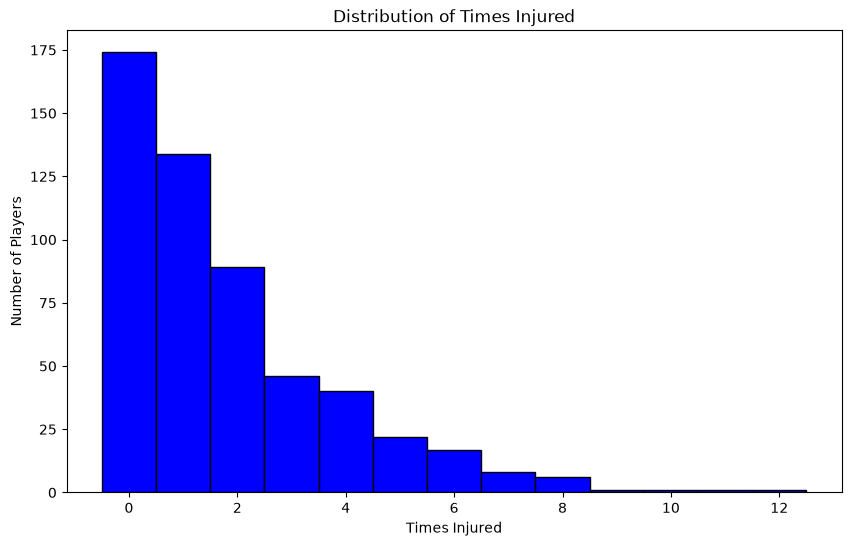

In [19]:
#histogram of injuries
plt.figure(figsize=(10, 6))
plt.hist(df['times_injured'], bins=range(0, df['times_injured'].max() + 2), edgecolor='black', align='left', color='blue')
plt.title('Distribution of Times Injured')
plt.xlabel('Times Injured')
plt.ylabel('Number of Players')
plt.show()

In [20]:
# value counts and percent for categorical columns
categories = ['position', 'draft_year', 'draft_round', 'draft_number', 'salary_tier', 'times_injured']

for col in categories:
    counts = df[col].value_counts(sort=False)
    # sort years and picks as numbers so 2 comes before 10, with Undrafted last
    if col in ['draft_year', 'draft_number']:
        counts = counts.sort_index(key=lambda x: pd.to_numeric(x, errors='coerce'))
    else:
        counts = counts.sort_index()
    display(pd.DataFrame({'count': counts, 'percent': (counts / len(df) * 100).round(1)}))

,count,percent
position,,
Center,95,17.6
Center-Power Forward,2,0.4
Point Guard,97,18.0
Point Guard-Shooting Guard,4,0.7
Power Forward,96,17.8
Power Forward-Small Forward,1,0.2
Shooting Guard,135,25.0
Shooting Guard-Small Forward,9,1.7
Small Forward,101,18.7


,count,percent
draft_year,,
2001,1,0.2
2003,2,0.4
2004,3,0.6
2005,1,0.2
2006,5,0.9
2007,5,0.9
2008,13,2.4
2009,12,2.2
2010,11,2.0


,count,percent
draft_round,,
1,249,46.1
2,127,23.5
Undrafted,164,30.4


,count,percent
draft_number,,
1,11,2.0
2,8,1.5
3,12,2.2
4,11,2.0
5,12,2.2
...,...,...
57,1,0.2
58,4,0.7
59,1,0.2


,count,percent
salary_tier,,
Under $2.5M,252,46.7
$2.5M to $5M,90,16.7
$5M to $15M,103,19.1
$15M to $30M,55,10.2
$30M+,40,7.4


,count,percent
times_injured,,
0,174,32.2
1,134,24.8
2,89,16.5
3,46,8.5
4,40,7.4
5,22,4.1
6,17,3.1
7,8,1.5
8,6,1.1


Value counts

Draft pick has 61 different values (picks 1 to 60 plus Undrafted), so its table is long, but I included it so every categorical column is covered. I show times injured as a table too because it is a count with only 13 different values.

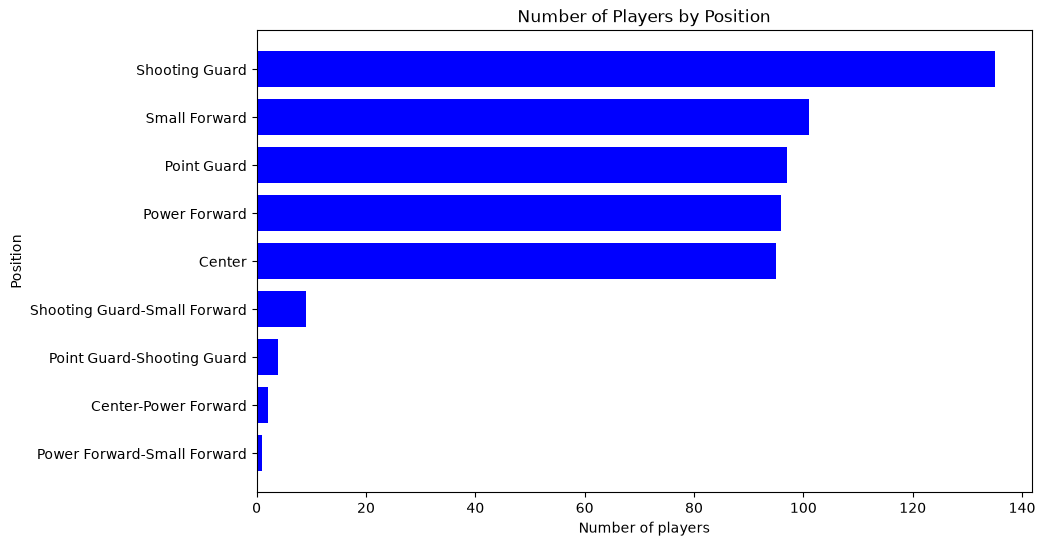

In [21]:
# bar chart of position

position_counts = df['position'].value_counts()

y = position_counts.values
n = len(y)
x = np.arange(n)

plt.figure(figsize=(10, 6))
plt.barh(x, y, height=.75, color='blue')
plt.title('Number of Players by Position')
plt.xlabel('Number of players')
plt.ylabel('Position')
plt.yticks(x, position_counts.index)
plt.gca().invert_yaxis()
plt.show()

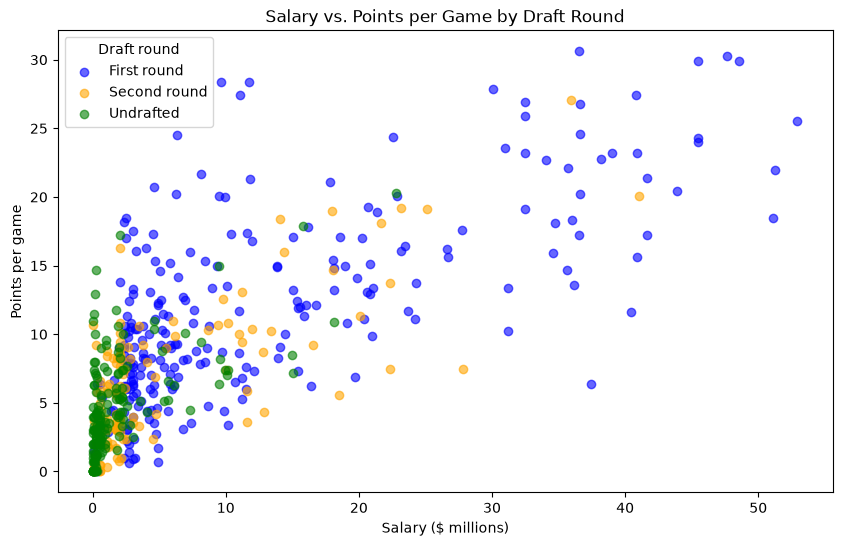

In [22]:
# scatter plot of salary vs points by draft round
groups = ['1', '2', 'Undrafted']
names = ['First round', 'Second round', 'Undrafted']
colors = ['blue', 'orange', 'green']

plt.figure(figsize=(10, 6))
for i in range(len(groups)):
    subset = df[df['draft_round'] == groups[i]]
    plt.scatter(subset['salary'] / 1000000, subset['points'], color=colors[i], label=names[i], alpha=0.6)

plt.title('Salary vs. Points per Game by Draft Round')
plt.xlabel('Salary ($ millions)')
plt.ylabel('Points per game')
plt.legend(title='Draft round')
plt.show()


In [23]:
# salary tier vs draft round
table = df.reset_index()
pd.crosstab(table['salary_tier'], table['draft_round'])

draft_round,1,2,Undrafted
salary_tier,,,
Under $2.5M,31,84,137
$2.5M to $5M,71,11,8
$5M to $15M,70,19,14
$15M to $30M,39,11,5
$30M+,38,2,0


## What I learned about the data:

Most players were placed on the injured list only a few times: 74% had 0 to 2 placements, while about a quarter had 3 or more, up to a maximum of 12. Almost every player (97%) is listed at a single position. Shooting guard is the most common at 25%, and the other four positions are split almost evenly at about 18% each. Salaries are very uneven. Nearly half of players (47%) earn under $2.5M, while only 40 players (7%) earn more than $30M, which is why the average salary ($7.6M) is much higher than the median ($2.8M). First round picks dominate the top of the pay scale: they make up 77 of the 95 players earning over $15M, and no undrafted player earns more than $30M.

# Section 5: Research Question Analysis

# Question 1:

How strongly is a player’s salary related to their points, rebounds, and assists per game?

Analysis approach: I used a correlation table to measure how strongly salary is connected to points, rebounds and assists. I used Spearman correlation instead of the default Pearson because salary is very skewed (the average is $7.6M but the median is only $2.8M), and Spearman ranks the players so a few max contracts have much less influence on the result. Next, I made a bar chart of average points, rebounds and assists in each salary tier to see whether players in higher tiers actually produce more. Finally, I made scatter plots of salary vs rebounds and salary vs assists with trend lines to show the relationship player by player. Points vs salary was already shown in Section 4. The trend lines are straight lines fitted to the raw values, so they only show the direction of each relationship. The strength of each relationship comes from the Spearman correlations.

In [24]:
# correlation between salary and performance
stats_cols = ['salary', 'points', 'rebounds', 'assists']

corr = df[stats_cols].corr(method='spearman')
corr.round(2)

,salary,points,rebounds,assists
salary,1.00,0.74,0.64,0.62
points,0.74,1.00,0.75,0.77
rebounds,0.64,0.75,1.00,0.54
assists,0.62,0.77,0.54,1.00


In [25]:
# compare points per game and points per 36 minutes 

regulars = df[df['games'] >= min_games].copy()
regulars['points_per_36'] = regulars['points'] / regulars['minutes'] * 36
regulars[['salary', 'points', 'points_per_36']].corr(method='spearman').round(2)

,salary,points,points_per_36
salary,1.00,0.67,0.46
points,0.67,1.00,0.79
points_per_36,0.46,0.79,1.00


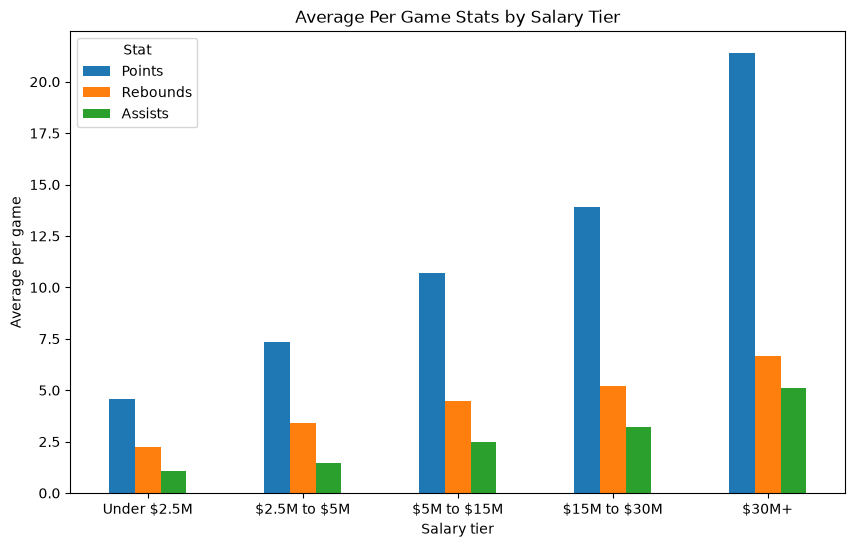

,points,rebounds,assists
salary_tier,,,
Under $2.5M,4.6,2.2,1.1
$2.5M to $5M,7.4,3.4,1.5
$5M to $15M,10.7,4.5,2.5
$15M to $30M,13.9,5.2,3.2
$30M+,21.4,6.7,5.1


In [26]:
# bar chart of average points, rebounds, and assists by salary tier

salary_means = df.groupby('salary_tier', observed=True)[['points', 'rebounds', 'assists']].mean()
salary_means.plot(kind='bar', figsize=(10, 6))
plt.title('Average Per Game Stats by Salary Tier')
plt.xlabel('Salary tier')
plt.ylabel('Average per game')
plt.xticks(rotation=0)
plt.legend([stat.title() for stat in salary_means.columns], title='Stat')
plt.show()

salary_means.round(1)

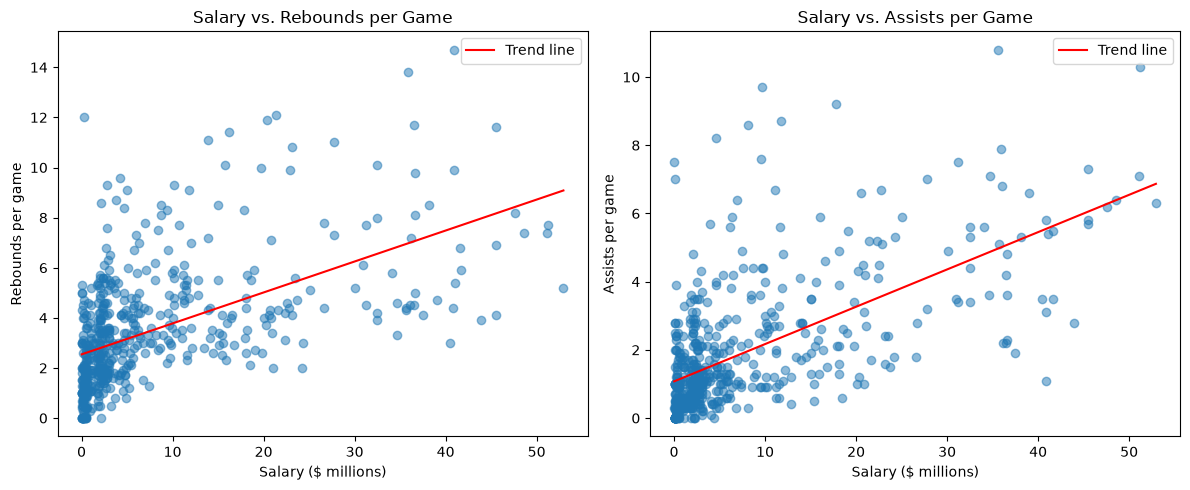

In [27]:
# scatter plot of salary vs rebounds and assists with trend lines

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, stat in zip(axes, ['rebounds', 'assists']):
    x = df['salary'] / 1000000
    ax.scatter(x, df[stat], alpha=0.5)
    slope, intercept = np.polyfit(x, df[stat], 1)
    ax.plot(x, slope * x + intercept, color='red', label='Trend line')
    ax.set_title(f'Salary vs. {stat.title()} per Game')
    ax.set_xlabel('Salary ($ millions)')
    ax.set_ylabel(f'{stat.title()} per game')
    ax.legend()
plt.tight_layout()
plt.show()

Results

Salary has a moderately strong to strong positive relationship with all three stats, and points have the strongest link to salary. Points had the highest correlation with salary (0.74), followed by rebounds (0.64) and assists (0.62). The bar chart shows the same pattern: average points rise in every salary tier, from 4.6 per game for players under $2.5M to 21.4 for players over $30M, while rebounds and assists rise more gradually. The scatter plots show that the relationship holds overall but has a lot of spread, with some lower paid players producing well and some highly paid players producing less.

Part of this relationship comes from playing time. Higher paid players play more minutes (a Spearman correlation of 0.73, shown in Question 3). To check this, I looked only at players with at least 20 games and compared salary to points per 36 minutes, which measures scoring at equal playing time. For these players, the correlation between salary and points per game was 0.67, slightly lower than the 0.74 for all players, and it dropped to 0.46 for points per 36 minutes. So higher paid players do score more per minute, but much of their higher scoring comes from being on the court longer. Salary likely also reflects things these stats do not capture, such as defense, experience and contract timing.

# Question 2:

Do high draft picks earn more and score more than second round and undrafted players?

Analysis approach: To compare undrafted players with drafted players, I first had to turn “Undrafted” into a number. I set undrafted players to round 3 and pick 61, since the draft only has 2 rounds and 60 picks, so this places them after the last pick. Then I ran a Spearman correlation between draft round, draft pick, salary and points. My code finds the last real pick and round in the data and adds one, so these numbers are not typed in by hand. Spearman fits here because draft position is a ranking, not a measurement, and it only uses the order of the values, so any placeholder above 60 would give the same result. What matters is the choice to rank undrafted players after the last pick. Finally, I made boxplots of salary and points per game by draft round. I chose boxplots instead of bar charts because they show the median and the full spread of each group, so a few highly paid stars do not hide what a typical player in each round earns and scores.

In [28]:
# change undrafted players into the pick and round after the last real ones
last_pick = pd.to_numeric(df['draft_number'], errors='coerce').max()
last_round = pd.to_numeric(df['draft_round'], errors='coerce').max()

df2 = df.copy()
df2['draft_number'] = df['draft_number'].replace('Undrafted', last_pick + 1).astype(int)
df2['draft_round'] = df['draft_round'].replace('Undrafted', last_round + 1).astype(int)
print(f"Undrafted players set to pick {int(last_pick + 1)} and round {int(last_round + 1)}")

Undrafted players set to pick 61 and round 3


In [29]:
# correlation between draft round, draft pick, salary, and points

draft_corr = df2[['draft_round', 'draft_number', 'salary', 'points']].corr(method='spearman')
draft_corr.round(2)

,draft_round,draft_number,salary,points
draft_round,1.00,0.94,-0.64,-0.50
draft_number,0.94,1.00,-0.66,-0.54
salary,-0.64,-0.66,1.00,0.74
points,-0.50,-0.54,0.74,1.00


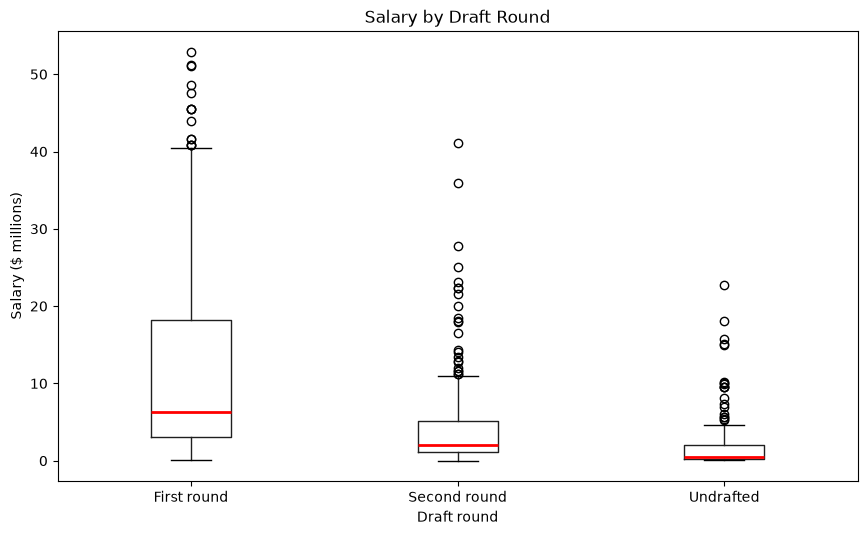

In [30]:
# boxplot of salary by draft round

df2.assign(salary_m=df2['salary'] / 1000000).boxplot(column='salary_m', by='draft_round', figsize=(10, 6), grid=False, medianprops={'color': 'red', 'linewidth': 2})
plt.suptitle('')
plt.title('Salary by Draft Round')
plt.xlabel('Draft round')
plt.xticks([1, 2, 3], names)
plt.ylabel('Salary ($ millions)')
plt.show()

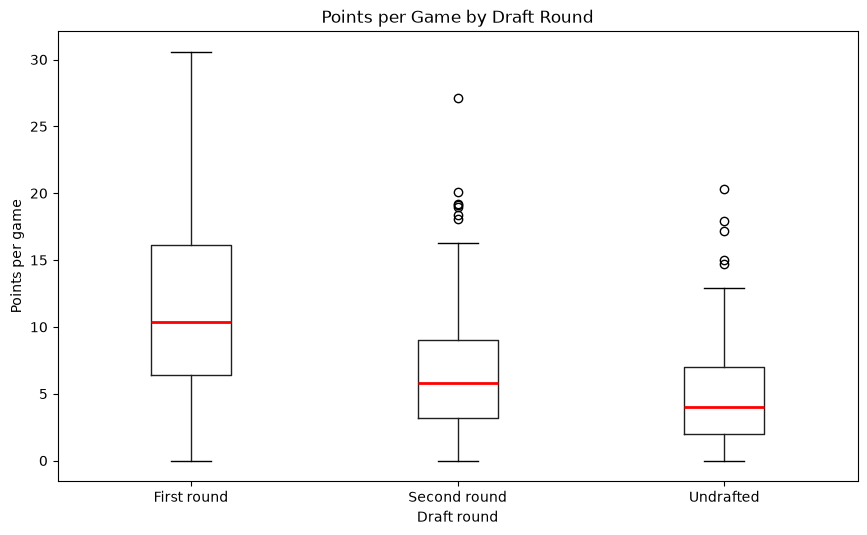

In [31]:
# boxplot of points by draft round

df2.boxplot(column='points', by='draft_round', figsize=(10, 6), grid=False, medianprops={'color': 'red', 'linewidth': 2})
plt.suptitle('')
plt.title('Points per Game by Draft Round')
plt.xlabel('Draft round')
plt.xticks([1, 2, 3], names)
plt.ylabel('Points per game')
plt.show()

In [32]:
# how many first round picks are past their four year rookie contract
first_round = df[df['draft_round'] == '1']
print(f"First round picks drafted in 2017 or earlier: {(pd.to_numeric(first_round['draft_year']) <= 2017).sum()} of {len(first_round)}")

# median salary, points, and minutes by draft round (3 = undrafted)
df2.groupby('draft_round')[['salary', 'points', 'minutes']].median()

First round picks drafted in 2017 or earlier: 154 of 249


,salary,points,minutes
draft_round,,,
1,6354744.0,10.4,24.8
2,2061329.0,5.8,16.3
3,534959.0,4.0,12.8


Results: 

Players drafted earlier earned more and scored more than second round and undrafted players. Draft pick number had a negative correlation with salary (−0.66) and with points (−0.54), and draft round showed a similar pattern (−0.64 and −0.50). A lower pick number means a player was drafted earlier, so the negative values mean earlier picks had higher salaries and more points. The salary boxplot shows the median salary dropping from about $6.4M for first round picks to about $2.1M for second round picks and about $0.5M for undrafted players. First round picks had the widest range of salaries, and all three groups had high salary outliers. The points boxplot shows the same order, with a median of 10.4 points per game for first round picks, 5.8 for second round picks and 4.0 for undrafted players.

Some of this gap comes from the way players are signed. First round picks get guaranteed rookie contracts that pay more the earlier they are picked, while most second round and undrafted players sign cheap deals. The crosstab in Section 4 shows this: 84 of 127 second round picks and 137 of 164 undrafted players earn under $2.5M. First round picks also get more playing time, with a median of 24.8 minutes per game compared to 16.3 for second round picks and 12.8 for undrafted players, which gives them more chances to score. The rookie contract scale only explains part of the gap, though. First round rookie contracts run up to four years (two guaranteed seasons plus two team options), and 154 of the 249 first round picks were drafted in 2017 or earlier (printed above the median table), so most first round picks here are veterans on later contracts. Also, second round and undrafted players who are still in the league years later are likely the stronger ones, since weaker players tend to leave the league, so the groups are not a perfectly even comparison. So earlier picks do earn and score more, but draft position is not the only reason.


# Question 3: 

Are higher paid players placed on the injured list more often than lower paid players?

Analysis approach: I first ran a Spearman correlation between times injured and salary to measure whether players who earn more are placed on the injured list more often. I also included games played and minutes per game, to check whether playing time explains the relationship, since players who are on the court more have more chances to get hurt. I used Spearman because these variables are skewed: salary has a few very large contracts, and times injured is mostly low numbers, with about a third of players having no placements other than COVID ones. Spearman ranks the values, so a handful of extreme cases have much less influence on the result. I then made a bar chart of average times injured in each salary tier, to see whether injured list placements rise steadily as pay goes up. Because many of the lowest paid players barely played, I repeated the correlation using only players with at least 20 games. Finally, I split those players into thirds by minutes per game and by salary and compared their average times injured in a table, to see whether higher paid players still get injured more when they are in the same minutes group. I also show the average minutes in each group, to check how similar the playing time really is. Last, I checked whether age explains the link, since higher paid players tend to be older.

In [33]:
# correlation between injury, salary, and playing time

injury_corr = df[['times_injured', 'salary', 'games', 'minutes']].corr(method='spearman')
injury_corr.round(2)


,times_injured,salary,games,minutes
times_injured,1.00,0.46,0.24,0.36
salary,0.46,1.00,0.66,0.73
games,0.24,0.66,1.00,0.68
minutes,0.36,0.73,0.68,1.00


In [34]:
# check how much playing time explains the injury relationship

low_paid = df[df['salary'] < low_pay_cutoff]
print(f"Players earning under ${low_pay_cutoff / 1000000:.0f}M: {len(low_paid)}, median games played: {low_paid['games'].median()}, played 10 or fewer games: {(low_paid['games'] <= 10).sum()}")

regulars = df[df['games'] >= min_games].copy()
print(f"Players with {min_games}+ games: {len(regulars)}")
regulars[['times_injured', 'salary', 'games', 'minutes']].corr(method='spearman').round(2)

Players earning under $1M: 138, median games played: 7.0, played 10 or fewer games: 84
Players with 20+ games: 396


,times_injured,salary,games,minutes
times_injured,1.00,0.33,-0.06,0.33
salary,0.33,1.00,0.32,0.69
games,-0.06,0.32,1.00,0.53
minutes,0.33,0.69,0.53,1.00


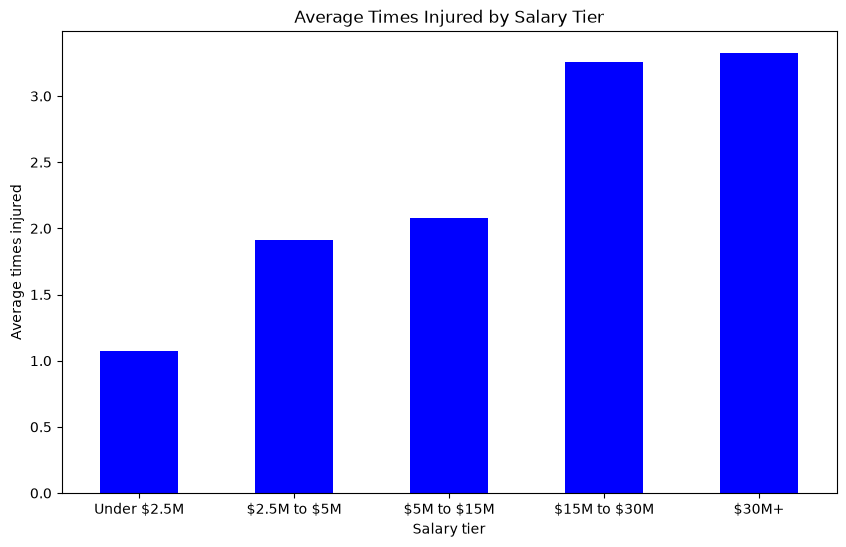

salary_tier
Under $2.5M     1.07
$2.5M to $5M    1.91
$5M to $15M     2.08
$15M to $30M    3.25
$30M+           3.32
Name: times_injured, dtype: float64

In [35]:
#bar chart between injury and salary_tier

injury_means = df.groupby('salary_tier', observed=True)['times_injured'].mean()
injury_means.plot(kind='bar', figsize=(10, 6), color='blue')
plt.title('Average Times Injured by Salary Tier')
plt.xlabel('Salary tier')
plt.ylabel('Average times injured')
plt.xticks(rotation=0)
plt.show()

injury_means.round(2)

In [36]:
# compare injuries at the same playing time

regulars['minutes_tier'] = pd.qcut(regulars['minutes'], 3, labels=['Low minutes', 'Mid minutes', 'High minutes'])
regulars['pay_tier'] = pd.qcut(regulars['salary'], 3, labels=['Low pay', 'Mid pay', 'High pay'])
display(regulars.pivot_table(index='minutes_tier', columns='pay_tier', values='times_injured', aggfunc='mean', observed=True).round(2))

# number of players in each group
display(regulars.pivot_table(index='minutes_tier', columns='pay_tier', values='times_injured', aggfunc='count', observed=True))

# average minutes in each group, to check that playing time is similar
regulars.pivot_table(index='minutes_tier', columns='pay_tier', values='minutes', aggfunc='mean', observed=True).round(1)

pay_tier,Low pay,Mid pay,High pay
minutes_tier,,,
Low minutes,1.30,1.65,2.09
Mid minutes,1.33,1.84,2.29
High minutes,1.62,2.39,3.45


pay_tier,Low pay,Mid pay,High pay
minutes_tier,,,
Low minutes,81,40,11
Mid minutes,43,61,28
High minutes,8,31,93


pay_tier,Low pay,Mid pay,High pay
minutes_tier,,,
Low minutes,12.0,12.9,16.0
Mid minutes,21.6,21.7,23.8
High minutes,30.0,31.3,32.3


In [37]:
# check whether age explains the link (age comes from the stats file, not cleaned_data.csv)
ages = pd.read_csv(stats_path + '/NBA Player Stats and Salaries_2010-2025.csv')
ages = ages[ages['Year'] == season][['Player', 'Age']]
ages.columns = ['player', 'age']
ages['player'] = ages['player'].apply(clean_name)
ages = ages.set_index('player')

age_check = df.join(ages)
print(f"Players missing an age: {age_check['age'].isnull().sum()}")
age_check[['times_injured', 'salary', 'minutes', 'age']].corr(method='spearman').round(2)

Players missing an age: 0


,times_injured,salary,minutes,age
times_injured,1.00,0.46,0.36,0.01
salary,0.46,1.00,0.73,0.32
minutes,0.36,0.73,1.00,0.17
age,0.01,0.32,0.17,1.00


Age check

Age is in the stats file, but I left it out of the final dataset because none of my questions are about age. I pull it in here only to test whether older players explain the injury pattern.

Results:

Higher paid players were placed on the injured list more often, and playing time explains a large part of this. Across all players, salary had a moderate positive correlation with times injured (0.46), higher than minutes per game (0.36) or games played (0.24). The bar chart shows the average number of placements rising from about 1.1 for players under $2.5M to about 3.3 for players earning $15M to $30M and over $30M.

However, many of the lowest paid players barely played. The 138 players who earned under $1M played a median of only 7 games, and 84 of them played 10 games or fewer. Some of these may have been short contracts signed during the 2021-22 COVID outbreak, and with so few games they had few chances to be placed on the injured list. When I looked only at the 396 players with at least 20 games, the correlation between salary and times injured dropped to 0.33, the same as minutes per game (0.33). Games played had almost no correlation (−0.06), which makes sense because getting injured makes a player miss games, so games played is not a good measure of playing time here.

To check whether pay still matters when playing time is similar, I compared players in the same minutes group. In every minutes group, higher paid players were placed on the injured list more often. The most reliable comparison is the mid minutes group, where every pay group has at least 28 players and similar average minutes (21.6 to 23.8), and the average went from 1.33 placements for the lowest paid third to 2.29 for the highest paid third. The high minutes group shows a bigger gap (1.62 to 3.45) at similar minutes (30.0 to 32.3), but only 8 players were in its low pay group, so that average is less reliable. In the low minutes group, the highest paid players averaged 16.0 minutes compared to 12.0 for the lowest paid, so part of that gap may still come from playing time, and only 11 players were in its high pay group. So higher paid players are placed on the injured list more partly because they play more. They still had more placements than lower paid players with similar minutes, which suggests pay may matter on its own, but this gap is smaller than the gap across all players, the groups are small, and I did not test whether these gaps are statistically significant, so it is a pattern to test further rather than a firm result. One possible reason is that teams are more careful with their most expensive players and hold them out sooner for minor injuries. I also checked age, since higher paid players tend to be older. Age had a correlation of 0.32 with salary but almost none with times injured (0.01), so age does not appear to explain why higher paid players are placed on the injured list more often.


# Section 6: Overall Conclusion

What I learned: Salary in the NBA lines up with production, but not as directly as I expected. Higher paid players scored, rebounded and passed more, but a large part of their scoring advantage came from simply playing more minutes. Draft position was also linked to pay and scoring. First round picks earned more and scored more than second round and undrafted players, partly because of guaranteed rookie contracts and more playing time. The most surprising result was injured list placements. Higher paid players were placed on the injured list more often, and even when I compared players in the same minutes group, the highest paid players still had the most placements, although those gaps were smaller and came from small groups. Before this project, I assumed injured list placements were mostly random, but the data suggests they are connected to how much a player plays and possibly to how much they are paid.

Limitations: This analysis only covers one season, and 2021-22 was unusual because of the COVID outbreak and the short contracts teams signed to fill their rosters. The stats file was also missing 65 of the 605 players listed in the draft file for 2021-22, including starters like Deandre Ayton and Gary Trent Jr. These players do not appear to be missing at random. 38 of the 65 missing players have a suffix like Jr. or initials like PJ, compared to only 14 of the 540 players who were included (both counted with the draft file's spelling in Section 3), and some of the rest go by nicknames or have apostrophes in their names. This suggests the original dataset had trouble matching some names to salaries. Because of this, the results may not fully represent the whole league. The injury data counts how many times a player was placed on the injured list, not how many games they missed, so a one game absence counts the same as a season ending injury, and placements for illness count the same as physical injuries. Also, 138 of the 1,105 placements I kept (shown in the injury cleaning step) list no reason at all, so a COVID placement recorded without the health and safety note would still be counted. Another 4 placements only say the player was "not with team," which may not be an injury at all. Salary is also based on when a contract was signed, so a young star on a rookie contract can look underpaid compared to their production. The minutes group comparisons in Question 3 use small groups (as few as 8 players), and I did not test whether those gaps are statistically significant. Finally, these are correlations, so they show which things move together but not what causes what.

What I would explore next: I would add more seasons to see if these patterns hold outside of the COVID year, and use games missed instead of injured list placements to measure how serious each injury was. I would also add years in the league and contract type (rookie deal, minimum deal or max deal), since salary depends on when and how a contract was signed. Age did not explain the salary and injury link in this season, so contract type and injury history are the next things to test.

Recommendations: Anyone judging whether a contract is worth it, such as fans, reporters or analysts, should look at production per minute alongside per game totals, since per game stats reward players who are already getting more minutes. This fits with the per minute stats that analysts commonly use. Second round and undrafted players may be worth a closer look because they cost much less, and the scatter plot shows some of them producing well for their salary, although I did not directly measure value per dollar. Teams paying large contracts may also want to plan for those players being placed on the injured list more often, by keeping solid backup players on the roster.
